<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/gg_lockup.png" alt="Global Gateway · European Union" height="64"/>

**Financé par l'Union européenne** · Programme de partenariat spatial Afrique–UE · Renforcement des alertes précoces en Afrique (SEWA)

# Les six prochains après-midi au Sénégal, à 9 km 🌡️
### Données ouvertes et gratuites de l'ECMWF · IFS 9 km · sans compte

> ⚠️ **Traduction :** ce notebook a été traduit de l'anglais avec l'aide de l'IA et relu au mieux de nos possibilités. En cas de doute, la [version anglaise](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/heat_forecast.ipynb) fait foi. Signalez toute erreur sur [GitHub](https://github.com/piddy376/visits-weather-notebooks/issues).

🌐 [English](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/heat_forecast.ipynb) · [Français](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/heat_forecast_fr.ipynb) · [Português](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/heat_forecast_pt.ipynb)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/heat_forecast_fr.ipynb)

La prévision à 9 km de l'ECMWF (IFS) est en **données ouvertes** : sans identifiant, sans frais. Ce notebook
télécharge la température à 2 m pour 15 h UTC (15 h à Dakar) sur chacun des six prochains jours, affiche la chaleur
de chaque après-midi dans six villes du Sénégal et cartographie le plus chaud.

**Ce qu'il vous faut :** un compte Google (pour utiliser Colab). Aucun autre compte, aucun frais, rien à installer. Tout tourne sur les ordinateurs de Google : les données y sont téléchargées, pas sur votre
téléphone ou votre ordinateur, donc une connexion lente ou mobile suffit.

| Données | Ce que ce notebook utilise | Licence |
|---|---|---|
| Prévision IFS de l'ECMWF, 9 km (0,1°) | Température à 2 m à 15 h UTC, six jours, dernier run | CC BY 4.0, données ouvertes |

**Outils :** [earthkit](https://earthkit.ecmwf.int), les outils Python libres et gratuits de l'ECMWF pour les données météo et climat.

*Cliquez sur **Exécution → Tout exécuter** (Runtime → Run all). La première exécution prend quelques minutes, surtout pour installer les outils.*

Mis en œuvre par :&nbsp;&nbsp;<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/ECMWF_Core_Logo_RGB.png" alt="ECMWF" height="30"/>

In [ ]:
# Installer les outils libres (Colab / nouvelle machine). Quelques minutes la première fois.
%pip install -q "earthkit-data[ecmwf-opendata]" earthkit-plots ecmwf-opendata

In [2]:
import pyproj                     # à importer avant earthkit.data (évite un plantage à la fermeture)
import datetime as dt
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import numpy as np
from ecmwf.opendata import Client

JOURS = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]
MOIS = ["janvier", "février", "mars", "avril", "mai", "juin", "juillet", "août", "septembre", "octobre",
        "novembre", "décembre"]
def jour(d): return f"{JOURS[d.weekday()]} {d.day} {MOIS[d.month - 1]}"     # dates en français
def date(d): return f"{d.day} {MOIS[d.month - 1]} {d.year}"

## 1 · Choisir la zone

In [3]:
AREA  = [17.5, -18.5, 11.5, -10.5]          # nord, ouest, sud, est : le Sénégal et la Gambie
STEPS = [15 + 24 * d for d in range(6)]     # 15 h UTC aujourd'hui et les cinq jours suivants (Dakar est à l'heure UTC)
CITIES = [("Dakar", 14.716, -17.467), ("Saint-Louis", 16.018, -16.489), ("Touba", 14.850, -15.883),
          ("Tambacounda", 13.771, -13.667), ("Ziguinchor", 12.583, -16.272), ("Kédougou", 12.557, -12.174)]

def label_cities(ax):
    for name, la, lo in CITIES:
        ax.scatter([lo], [la], s=36, color="#ffd23f", edgecolors="#1a1a1a", linewidths=0.8, zorder=10,
                   transform=ccrs.PlateCarree())
        ax.text(lo, la, f"  {name}", transform=ccrs.PlateCarree(), fontsize=10, fontweight="bold", zorder=11,
                color="#1d2230", path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

## 2 · Télécharger la prévision à 9 km (données ouvertes de l'ECMWF)

In [4]:
for SOURCE in ("ecmwf", "aws", "google"):      # l'ECMWF d'abord, puis les miroirs cloud s'il est occupé
    try:
        result = Client(SOURCE).retrieve(time=0, step=STEPS, stream="oper", type="fc", levtype="sfc",
                                         param="2t", resol="0p1", target="t2m.grib2")   # resol="0p1" = 9 km
        break
    except Exception as err:
        print(f"{SOURCE} ne répond pas ({type(err).__name__}), essai du miroir suivant")
run = result.datetime
x = ekd.from_source("file", "t2m.grib2").to_xarray()
x = x.assign_coords(longitude=((x.longitude + 180) % 360) - 180).sortby("longitude")
x = x.sel(latitude=slice(AREA[0] + 0.5, AREA[2] - 0.5), longitude=slice(AREA[1] - 0.5, AREA[3] + 0.5))  # petite marge
t2m = x[list(x.data_vars)[0]] - 273.15                                            # kelvins -> °C
sdim = [d for d in t2m.dims if d not in ("latitude", "longitude")][0]
print(f"Prévision du {jour(run)} {run.year}, run de 00 h UTC")
for k, s in enumerate(STEPS):
    v = run + dt.timedelta(hours=s)
    towns = "  ".join(f"{n} {float(t2m.isel({sdim: k}).sel(latitude=la, longitude=lo, method='nearest')):.0f}°"
                      for n, la, lo in CITIES)
    print(f"  {jour(v):21s} 15 h UTC   {towns}")
hot = int(t2m.mean(["latitude", "longitude"]).argmax())                            # l'après-midi le plus chaud
day = run + dt.timedelta(hours=STEPS[hot])

By downloading data from the ECMWF open data dataset, you agree to the terms: Attribution 4.0 International (CC BY 4.0). Please attribute ECMWF when downloading this data.


Prévision du jeudi 19 novembre 2026, run de 00 h UTC
  jeudi 19 novembre     15 h UTC   Dakar 29°  Saint-Louis 29°  Touba 36°  Tambacounda 35°  Ziguinchor 32°  Kédougou 30°
  vendredi 20 novembre  15 h UTC   Dakar 30°  Saint-Louis 29°  Touba 37°  Tambacounda 36°  Ziguinchor 34°  Kédougou 31°
  samedi 21 novembre    15 h UTC   Dakar 33°  Saint-Louis 33°  Touba 38°  Tambacounda 38°  Ziguinchor 35°  Kédougou 33°
  dimanche 22 novembre  15 h UTC   Dakar 33°  Saint-Louis 33°  Touba 38°  Tambacounda 38°  Ziguinchor 34°  Kédougou 34°
  lundi 23 novembre     15 h UTC   Dakar 32°  Saint-Louis 30°  Touba 37°  Tambacounda 37°  Ziguinchor 35°  Kédougou 34°
  mardi 24 novembre     15 h UTC   Dakar 31°  Saint-Louis 27°  Touba 38°  Tambacounda 37°  Ziguinchor 35°  Kédougou 34°


## 3 · Cartographier l'après-midi le plus chaud

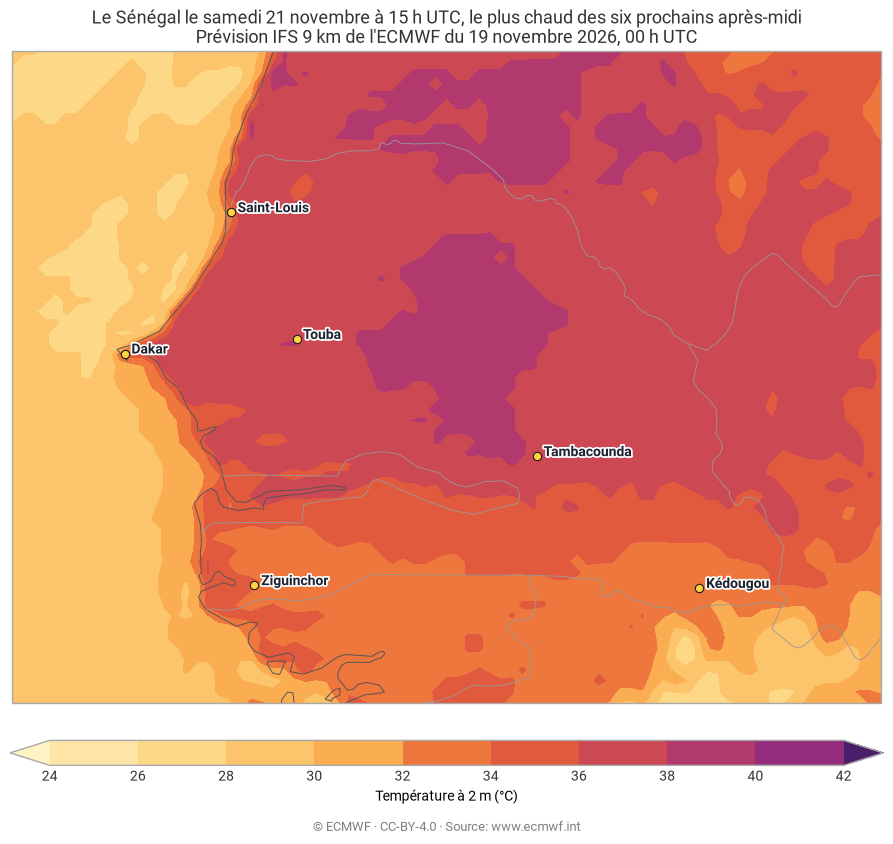

In [5]:
style = ekp.styles.Style(levels=[24, 26, 28, 30, 32, 34, 36, 38, 40, 42], colors=["#fff3c4", "#fdd27a", "#f99a3c", "#e0543e", "#a3307e", "#4a1f6a"], extend="both")
chart = ekp.Map(domain=[AREA[1], AREA[3], AREA[2], AREA[0]], figsize=(11, 8))
chart.contourf(t2m.isel({sdim: hot}), style=style)
chart.coastlines(linewidth=0.7); chart.borders(linewidth=0.6)
label_cities(chart.ax)
chart.legend(label="Température à 2 m (°C)")
chart.title(f"Le Sénégal le {jour(day)} à 15 h UTC, le plus chaud des six prochains après-midi\n"
            f"Prévision IFS 9 km de l'ECMWF du {date(run)}, 00 h UTC", fontsize=13)
chart.attribution("© ECMWF · CC-BY-4.0 · Source: www.ecmwf.int")
chart.save("heat_forecast_fr.png")
chart.show()

## 4 · À vous de jouer 🌍

- **La nuit :** remplacez `15` par `3` dans `STEPS` pour 03 h UTC, le moment le plus frais de la nuit.
- **Le vent :** ajoutez `"10u", "10v"` à `param` et tracez des flèches avec `chart.ax.quiver`.
- **Ailleurs :** changez `AREA`, par exemple `[16, -6, 9, 3]` pour le Burkina Faso.

### Données et licence
Les données ouvertes de l'ECMWF sont gratuites sous licence **Creative Commons CC-BY-4.0** :
`© ECMWF · Source: www.ecmwf.int · CC-BY-4.0 and ECMWF Terms of Use`. Sans compte, sans clé.

[Données ouvertes de l'ECMWF](https://www.ecmwf.int/en/forecasts/datasets/open-data) · [earthkit](https://earthkit.ecmwf.int)